# Bonus — LightGBM vs. XGBoost

**LightGBM** is another gradient-boosted trees library. It is trained here on **exactly the same features** (approach C), with the same
split, folds, outlier removal and class weights as XGBoost in `03_xgboost_tuning.ipynb`, and tuned the same way (Optuna, TPE, 100 trials).

We compare:
1. **how the trees are built** (with plots),
2. **the learning process** (loss and macro-F1 after every boosting round, training time),
3. **the results** on the test part.

## 1. Setup

In [1]:
import json
import time

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import xgboost as xgb
from optuna.samplers import TPESampler
from sklearn.metrics import ConfusionMatrixDisplay, f1_score, log_loss
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.utils.class_weight import compute_sample_weight

from common import (CLASS_LABELS, RANDOM_STATE, RESULTS_DIR, compute_scores, cross_validate, drop_outliers, fit_model,
                    load_processed, split_features_target)

setup = json.loads((RESULTS_DIR / "best_setup.json").read_text())
xgb_params = json.loads((RESULTS_DIR / "best_params.json").read_text())
xgb_metrics = json.loads((RESULTS_DIR / "final_metrics.json").read_text())
FIT_OPTIONS = {"remove_outliers": setup["remove_outliers"], "balance": setup["balance"]}

X, y = split_features_target(load_processed(setup["dataset"]))
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=setup["test_size"], stratify=y if setup["stratified"] else None, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=setup["k"], shuffle=True, random_state=RANDOM_STATE)
print("Training part:", X_train.shape, "| Test part:", X_test.shape)

Training part: (2344, 208) | Test part: (586, 208)


**One thread per LightGBM model.** On this small dataset (≈ 2300 houses), LightGBM is about 5× *faster* with 1 thread than with 8:
coordinating the threads costs more than it saves. Instead, Optuna runs several trials in parallel (section 4).
LightGBM also replaces spaces in feature names with `_`; importances are mapped back to the original names.

In [2]:
def make_lgb(**params):
    return lgb.LGBMClassifier(random_state=RANDOM_STATE, n_jobs=1, verbose=-1, **params)


def make_xgb(**params):
    return xgb.XGBClassifier(enable_categorical=True, random_state=RANDOM_STATE, n_jobs=1, **params)


def cv_scores(make_model):
    folds = cross_validate(make_model, X_train, y_train, cv, **FIT_OPTIONS)
    return {"train_f1": folds["train_f1"].mean(), "cv_f1": folds["val_f1"].mean(), "cv_f1_std": folds["val_f1"].std()}

## 2. How the trees are built

| | XGBoost | LightGBM |
|---|---|---|
| **Tree growth** | **level-wise** (depth-wise): splits *every* node of a level before going deeper → balanced trees | **leaf-wise** (best-first): always splits the *one leaf* with the largest loss reduction → deep, unbalanced trees |
| **Main size limit** | `max_depth` (default 6 → up to 64 leaves) | `num_leaves` (default 31); `max_depth` unlimited by default |
| **Split finding** | histogram of feature values (`tree_method="hist"`, default) | histogram (256 bins by default) |
| **Sparse features** | sparsity-aware: learns a default direction for missing values / zeros | **Exclusive Feature Bundling (EFB)**: merges features that are rarely non-zero at the same time — e.g. one-hot columns of the same category — into one feature, so fewer histograms are built |
| **Sampling** | row/column subsampling | row/column subsampling; optionally GOSS (keeps rows with large gradients) |
| **Minimum leaf size** | `min_child_weight` (sum of hessians) | `min_child_samples` (number of rows, default 20) + `min_child_weight` |
| **Multiclass** | one tree per class per round (softmax) | the same |

**Why it matters:** with the same number of leaves, a leaf-wise tree reduces the loss more, because every split goes where it helps
most. The risk: on small data it can grow very deep, narrow branches that fit individual houses → `num_leaves`, `max_depth` and
`min_child_samples` must limit it.

**Demonstration:** both libraries with the **same number of leaves** (at most 16), the same learning rate (0.1) and 100 rounds:
XGBoost limited by `max_depth = 4` (2⁴ = 16 leaves), LightGBM by `num_leaves = 16` with no depth limit.

In [3]:
X_fit, y_fit = drop_outliers(X_train, y_train)
weights = compute_sample_weight("balanced", y_fit)

demo_xgb = make_xgb(max_depth=4, learning_rate=0.1, n_estimators=100).fit(X_fit, y_fit, sample_weight=weights)
demo_lgb = make_lgb(num_leaves=16, learning_rate=0.1, n_estimators=100).fit(X_fit, y_fit, sample_weight=weights)


def xgb_tree_shapes(model):
    table = model.get_booster().trees_to_dataframe()
    rows = []
    for tree, nodes in table.groupby("Tree"):
        depth = {f"{tree}-0": 0}
        for _, node in nodes.iterrows():  # parents are listed before their children
            if node["Feature"] != "Leaf":
                depth[node["Yes"]] = depth[node["No"]] = depth[node["ID"]] + 1
        leaves = nodes.loc[nodes["Feature"] == "Leaf", "ID"]
        rows.append({"tree": tree, "leaves": len(leaves), "depth": max(depth[i] for i in leaves)})
    return pd.DataFrame(rows)


def lgb_tree_shapes(model):
    table = model.booster_.trees_to_dataframe()
    leaves = table[table["split_feature"].isna()]
    return leaves.groupby("tree_index").agg(leaves=("node_index", "size"), depth=("node_depth", "max")).assign(
        depth=lambda d: d["depth"] - 1).reset_index(names="tree")


shapes = pd.concat([xgb_tree_shapes(demo_xgb).assign(model="XGBoost (max_depth=4)"),
                    lgb_tree_shapes(demo_lgb).assign(model="LightGBM (num_leaves=16)")])
shapes.groupby("model")[["leaves", "depth"]].agg(["mean", "max"]).round(2)

leaves     depth    
                           mean max  mean max
model                                        
LightGBM (num_leaves=16)  15.98  16  8.52  14
XGBoost (max_depth=4)     11.79  16  4.00   4

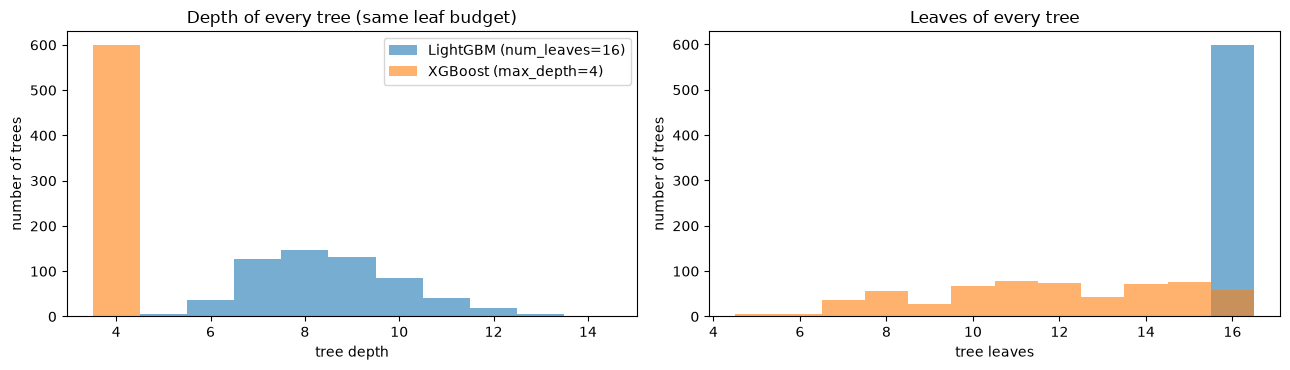

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, col in zip(axes, ["depth", "leaves"]):
    bins = np.arange(shapes[col].min(), shapes[col].max() + 2) - 0.5
    for name, group in shapes.groupby("model"):
        ax.hist(group[col], bins=bins, alpha=0.6, label=name)
    ax.set_xlabel(f"tree {col}"); ax.set_ylabel("number of trees")
axes[0].set_title("Depth of every tree (same leaf budget)"); axes[1].set_title("Leaves of every tree")
axes[0].legend()
plt.tight_layout()
plt.show()

**The same tree in both models** — round 1, class 3 (130k–180k, the largest class) — tree index 2 in both libraries
(6 trees per round, ordered by class).

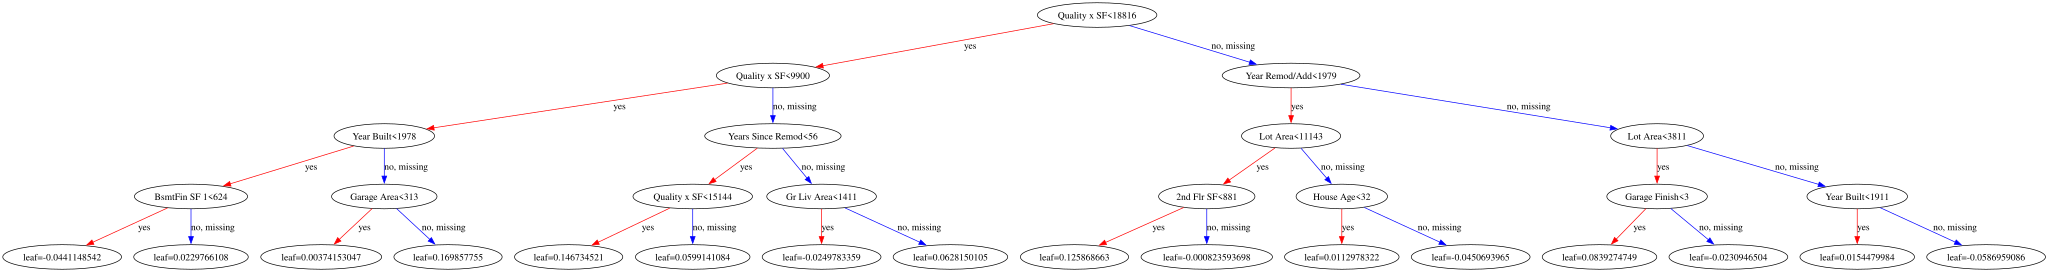

In [5]:
xgb.to_graphviz(demo_xgb, tree_idx=2)

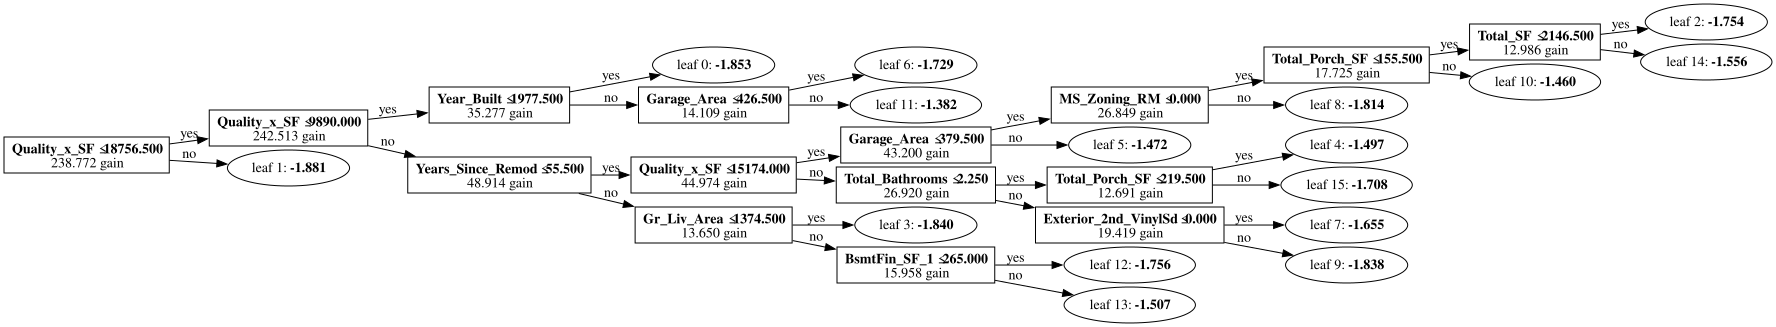

In [6]:
lgb.create_tree_digraph(demo_lgb, tree_index=2, show_info=["split_gain"])

In [7]:
demo_scores = pd.DataFrame({
    "XGBoost (max_depth=4)": cv_scores(lambda: make_xgb(max_depth=4, learning_rate=0.1, n_estimators=100)),
    "LightGBM (num_leaves=16)": cv_scores(lambda: make_lgb(num_leaves=16, learning_rate=0.1, n_estimators=100)),
}).T
demo_scores.round(4)

,train_f1,cv_f1,cv_f1_std
XGBoost (max_depth=4),0.9573,0.7358,0.0293
LightGBM (num_leaves=16),0.9979,0.7505,0.0421


**Interpretation — tree building**
- **The growth strategies are clearly visible.** With the same leaf budget (16), every XGBoost tree has depth exactly 4 (balanced,
  level by level), while LightGBM trees are 5 to 14 levels deep (mean 8.5): leaf-wise growth keeps splitting the most promising
  branch, producing long, unbalanced branches.
- **LightGBM always uses all 16 leaves**, XGBoost only 11.8 on average: a level-wise tree must split *every* node of a level,
  and nodes that cannot be split usefully (too few houses, no gain) stay leaves. LightGBM spends its leaves where the loss drops most.
- In the drawn trees (class 3), XGBoost splits every branch down to depth 4. LightGBM's first split (`Quality x SF` < 18,757)
  sends 717 expensive houses straight to a leaf — they are clearly not class 3 — and spends its remaining leaves on a branch of
  mid-sized, mid-quality houses that goes 9 levels deep: exactly the region where class 3 must be separated from classes 2 and 4.
- **Same budget, better use:** at 16 leaves LightGBM reaches CV macro-F1 0.751 vs. 0.736 for XGBoost — but also a training F1 of
  0.998 vs. 0.957: leaf-wise trees fit the training data faster, i.e. they have **more variance** for the same number of leaves.

## 3. Default LightGBM
LightGBM's defaults: 100 trees, `num_leaves` = 31, no depth limit, learning rate 0.1, `min_child_samples` = 20.

In [8]:
lgb_default = cv_scores(lambda: make_lgb())
xgb_default = cv_scores(lambda: make_xgb())
pd.DataFrame({"XGBoost default": xgb_default, "LightGBM default": lgb_default}).T.round(4)

,train_f1,cv_f1,cv_f1_std
XGBoost default,0.9982,0.7489,0.0324
LightGBM default,0.9982,0.7481,0.0393


**Interpretation — defaults:** both libraries reach the same CV macro-F1 with their defaults (0.749 vs. 0.748), and both fit the
training data almost perfectly (0.998) → the same high-variance situation as in `02`. LightGBM's fold-to-fold spread is a bit larger (0.039 vs. 0.032).

## 4. Optuna (TPESampler)
Same method as for XGBoost: TPE, 100 trials, 10-fold CV macro-F1 as objective, stored in the same SQLite file under its own study name.
**4 trials run in parallel** (each with one thread). TPE then proposes a new trial while 3 others are still running, so it uses
slightly less information per proposal than the sequential XGBoost search.

| Hyperparameter | Range | XGBoost equivalent |
|---|---|---|
| `num_leaves` | 8 – 128 (log) | — (XGBoost limits depth instead) |
| `max_depth` | 3 – 12 | `max_depth` |
| `learning_rate` | 0.01 – 0.3 (log) | `learning_rate` |
| `n_estimators` | 100 – 800 (step 50) | `n_estimators` |
| `min_child_samples` | 5 – 100 (log) | ≈ `min_child_weight` |
| `subsample` (+ `subsample_freq` = 1) | 0.5 – 1.0 | `subsample` |
| `colsample_bytree` | 0.5 – 1.0 | `colsample_bytree` |
| `reg_lambda`, `reg_alpha` | 0.001 – 50 (log) | `reg_lambda`, `reg_alpha` |
| `min_split_gain` | 0 – 1 | `gamma` |

`subsample_freq` = 1 is needed in LightGBM for row subsampling to be active at all (re-sample every round).

In [9]:
def lgb_objective(trial):
    params = {
        "num_leaves": trial.suggest_int("num_leaves", 8, 128, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "n_estimators": trial.suggest_int("n_estimators", 100, 800, step=50),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 100, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 50, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 50, log=True),
        "min_split_gain": trial.suggest_float("min_split_gain", 0, 1),
    }
    scores = cv_scores(lambda: make_lgb(**params))
    trial.set_user_attr("train_f1", scores["train_f1"])
    trial.set_user_attr("cv_f1_std", scores["cv_f1_std"])
    return scores["cv_f1"]


N_TRIALS = 100
STORAGE = f"sqlite:///{RESULTS_DIR / 'optuna_xgboost.db'}"
optuna.logging.set_verbosity(optuna.logging.WARNING)
lgb_study = optuna.create_study(study_name="lightgbm_approach_C", storage=STORAGE, direction="maximize",
                                sampler=TPESampler(n_startup_trials=10, seed=RANDOM_STATE), load_if_exists=True)

finished = len(lgb_study.get_trials(states=[optuna.trial.TrialState.COMPLETE]))
if finished < N_TRIALS:
    start = time.time()
    lgb_study.optimize(lgb_objective, n_trials=N_TRIALS - finished, n_jobs=4)
    print(f"Search took {(time.time() - start) / 60:.1f} min")

xgb_study = optuna.load_study(study_name="xgboost_approach_C", storage=STORAGE)
lgb_params = {**lgb_study.best_params, "subsample_freq": 1}
print(f"LightGBM: best CV macro-F1 {lgb_study.best_value:.4f} (trial {lgb_study.best_trial.number})")
print(f"XGBoost:  best CV macro-F1 {xgb_study.best_value:.4f} (trial {xgb_study.best_trial.number})")
pd.Series(lgb_study.best_params).to_frame("best value")

LightGBM: best CV macro-F1 0.7719 (trial 92)
XGBoost:  best CV macro-F1 0.7730 (trial 64)


,best value
num_leaves,39.000000
max_depth,4.000000
learning_rate,0.015145
n_estimators,750.000000
min_child_samples,21.000000
subsample,0.677157
colsample_bytree,0.602837
reg_lambda,0.038126
reg_alpha,0.125369
min_split_gain,0.041768


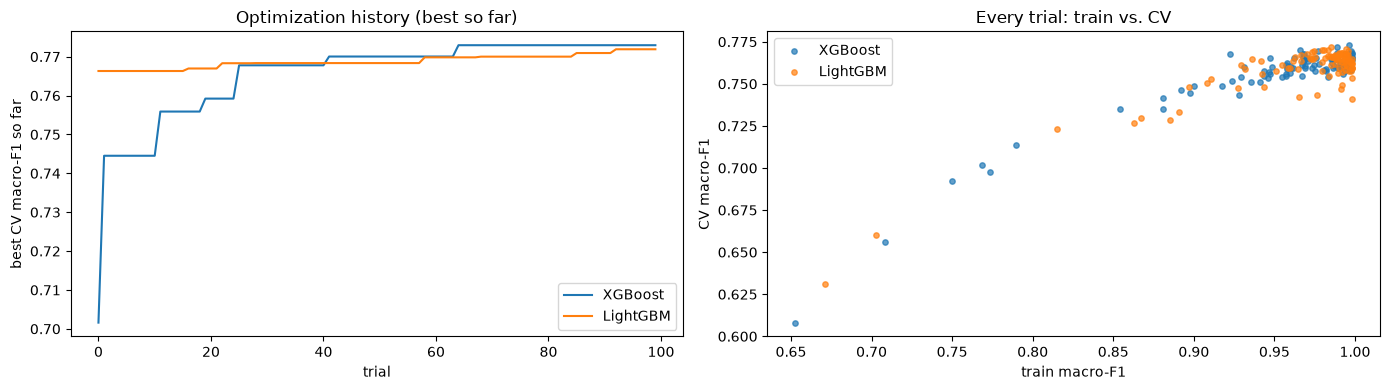

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for study, name in [(xgb_study, "XGBoost"), (lgb_study, "LightGBM")]:
    values = pd.Series([t.value for t in sorted(study.trials, key=lambda t: t.number)])
    axes[0].plot(values.cummax().values, label=name)
    train = [t.user_attrs["train_f1"] for t in study.trials]
    axes[1].scatter(train, [t.value for t in study.trials], s=15, alpha=0.7, label=name)
axes[0].set(xlabel="trial", ylabel="best CV macro-F1 so far", title="Optimization history (best so far)")
axes[1].set(xlabel="train macro-F1", ylabel="CV macro-F1", title="Every trial: train vs. CV")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

In [11]:
optuna.visualization.plot_param_importances(lgb_study)

**Shape of the tuned trees** (both models fitted on the training part with their best hyperparameters):

In [12]:
tuned_shapes = pd.concat([
    xgb_tree_shapes(fit_model(make_xgb(**xgb_params), X_train, y_train, **FIT_OPTIONS)).assign(model="XGBoost tuned"),
    lgb_tree_shapes(fit_model(make_lgb(**lgb_params), X_train, y_train, **FIT_OPTIONS)).assign(model="LightGBM tuned"),
])
tuned_shapes.groupby("model")[["leaves", "depth"]].agg(["mean", "max"]).round(2)

leaves     depth    
                 mean max  mean max
model                              
LightGBM tuned   9.82  16  3.93   4
XGBoost tuned    8.42  44  3.08   7

**Interpretation — Optuna**
- **Best CV macro-F1: LightGBM 0.772 vs. XGBoost 0.773** — practically identical; the difference is far below the CV uncertainty (≈ 0.01).
- **The search was ≈ 6× faster** (7.6 min vs. 44 min), mainly because 4 single-threaded trials ran in parallel; the XGBoost search ran
  one trial at a time with 8 threads, which is inefficient on a dataset this small. Not a fair speed comparison of the libraries —
  the per-round timing in section 5 is.
- **Optuna limited LightGBM's leaf-wise growth:** the best trial uses `max_depth` = 4, which caps every tree at 2⁴ = 16 leaves
  (its `num_leaves` = 39 can never be reached). On 2300 houses, deep leaf-wise trees overfit, so the search moved towards shallow trees —
  together with a **small learning rate (0.015) and many trees (750)**, `min_child_samples` = 21 and row/column subsampling ≈ 0.6–0.7.
- **Both tuned models converge to small trees:** ≈ 8–10 leaves and depth ≈ 3–4 on average. XGBoost's `max_depth` = 7 is rarely
  reached because `gamma` and `min_child_weight` prune splits without enough gain. Tuning makes the two algorithms more similar
  than their defaults are.

## 5. The learning process

How do both tuned models learn, round by round? The training part is split once more (stratified 80/20) into a **fit part**
and a **validation part**; both models are trained on the fit part (outliers removed, class weights) and evaluated on both parts
after every boosting round. The test part is still not used.
- **multi-class log-loss**: the quantity both models minimise (lower = better, probabilities closer to the truth),
- **macro-F1**: the metric we care about.

In [13]:
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE)
X_fit, y_fit = drop_outliers(X_fit, y_fit)
w_fit = compute_sample_weight("balanced", y_fit)

curve_xgb = make_xgb(**xgb_params).fit(X_fit, y_fit, sample_weight=w_fit,
                                       eval_set=[(X_fit, y_fit), (X_val, y_val)], verbose=False)
curve_lgb = make_lgb(**lgb_params).fit(X_fit, y_fit, sample_weight=w_fit, eval_X=(X_fit, X_val), eval_y=(y_fit, y_val),
                                       eval_metric="multi_logloss")

loss = {
    "XGBoost": (curve_xgb.evals_result()["validation_0"]["mlogloss"], curve_xgb.evals_result()["validation_1"]["mlogloss"]),
    "LightGBM": (curve_lgb.evals_result_["valid_0"]["multi_logloss"], curve_lgb.evals_result_["valid_1"]["multi_logloss"]),
}

STEP = 10
f1_curves = {}
for name, model in [("XGBoost", curve_xgb), ("LightGBM", curve_lgb)]:
    rounds = np.arange(STEP, model.n_estimators + 1, STEP)
    if name == "XGBoost":
        predict = lambda data, r: model.predict(data, iteration_range=(0, r))
    else:
        predict = lambda data, r: model.predict(data, num_iteration=r)
    f1_curves[name] = pd.DataFrame({"round": rounds,
                                    "fit": [f1_score(y_fit, predict(X_fit, r), average="macro") for r in rounds],
                                    "validation": [f1_score(y_val, predict(X_val, r), average="macro") for r in rounds]})

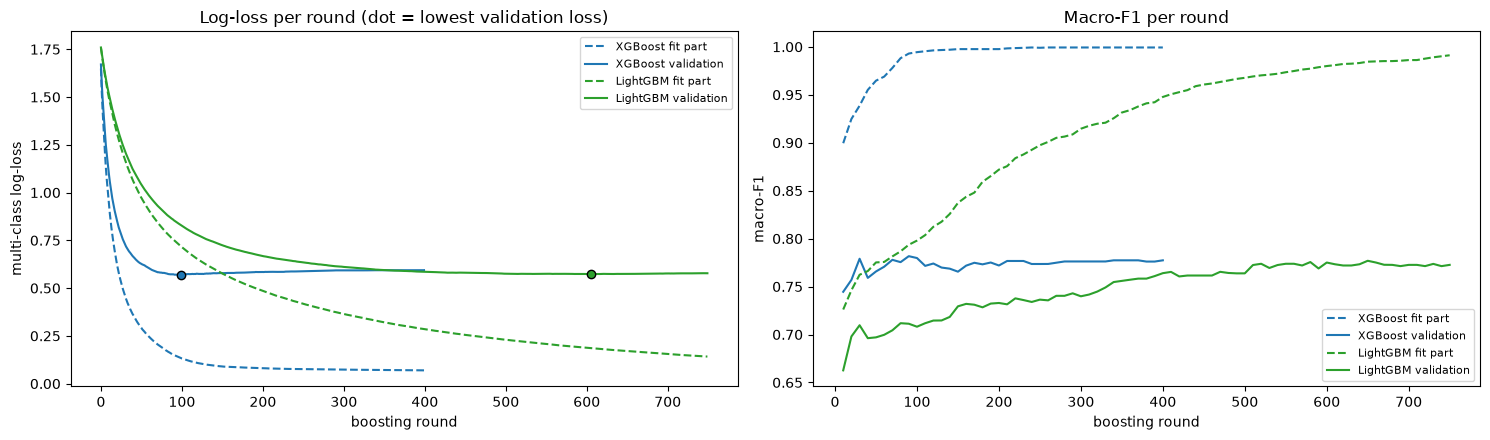

,XGBoost,LightGBM
rounds,400.0000,750.0000
round with lowest validation loss,100.0000,606.0000
lowest validation loss,0.5702,0.5736
validation loss at the end,0.5939,0.5778
best validation macro-F1,0.7817,0.7769
validation macro-F1 at the end,0.7774,0.7726


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
colors = {"XGBoost": "tab:blue", "LightGBM": "tab:green"}
for name, (train_loss, val_loss) in loss.items():
    axes[0].plot(train_loss, "--", color=colors[name], label=f"{name} fit part")
    axes[0].plot(val_loss, color=colors[name], label=f"{name} validation")
    best = int(np.argmin(val_loss))
    axes[0].scatter(best, val_loss[best], color=colors[name], edgecolors="black", zorder=3)
    curves = f1_curves[name]
    axes[1].plot(curves["round"], curves["fit"], "--", color=colors[name], label=f"{name} fit part")
    axes[1].plot(curves["round"], curves["validation"], color=colors[name], label=f"{name} validation")
axes[0].set(xlabel="boosting round", ylabel="multi-class log-loss", title="Log-loss per round (dot = lowest validation loss)")
axes[1].set(xlabel="boosting round", ylabel="macro-F1", title="Macro-F1 per round")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

pd.DataFrame({name: {"rounds": len(val_loss), "round with lowest validation loss": int(np.argmin(val_loss)) + 1,
                     "lowest validation loss": min(val_loss), "validation loss at the end": val_loss[-1],
                     "best validation macro-F1": f1_curves[name]["validation"].max(),
                     "validation macro-F1 at the end": f1_curves[name]["validation"].iloc[-1]}
              for name, (_, val_loss) in loss.items()}).round(4)

**Training time** of the final models on the whole training part (1 thread each, median of 5 runs):

In [15]:
def median_fit_seconds(make_model, runs=5):
    times = []
    for _ in range(runs):
        start = time.perf_counter()
        fit_model(make_model(), X_train, y_train, **FIT_OPTIONS)
        times.append(time.perf_counter() - start)
    return float(np.median(times))


timing = pd.DataFrame({
    "XGBoost": {"trees per class": xgb_params["n_estimators"], "seconds": median_fit_seconds(lambda: make_xgb(**xgb_params))},
    "LightGBM": {"trees per class": lgb_params["n_estimators"], "seconds": median_fit_seconds(lambda: make_lgb(**lgb_params))},
}).T
timing["ms per round"] = 1000 * timing["seconds"] / timing["trees per class"]
timing.round(3)

,trees per class,seconds,ms per round
XGBoost,400.0,1.629,4.072
LightGBM,750.0,1.392,1.856


**Interpretation — learning process**
- **XGBoost learns fast** (learning rate 0.082): its validation log-loss is lowest after ≈ 100 rounds and then **rises slightly**
  (0.570 → 0.594) while the fit-part loss keeps falling — the probabilities become over-confident (overfitting in the loss).
  Its validation macro-F1 is already ≈ 0.78 after ≈ 90 rounds and stays flat: the *ranking* of the classes no longer changes,
  only the confidence.
- **LightGBM learns slowly and smoothly** (learning rate 0.015): its validation loss keeps decreasing until round ≈ 600 and barely
  rises afterwards; the fit-part F1 climbs gradually instead of jumping to 1.0. This is the classic trade-off: small steps need
  more rounds but overfit later and more gently.
- Both end at the same validation macro-F1 (≈ 0.77–0.78); with early stopping XGBoost would need only ≈ 100 rounds.
- **Speed:** LightGBM needs ≈ 1.9 ms per round vs. ≈ 4.0 ms for XGBoost (6 trees per round each, 1 thread) — about **2× faster per
  round**. It runs almost twice as many rounds, so the total training time is similar (1.4 s vs. 1.6 s). Exclusive Feature Bundling is
  *not* the reason here: switching it off (`enable_bundle=False`) does not change LightGBM's training time on this data — the
  difference comes from the two implementations (and the smaller tuned trees).

## 6. Results on the test part
Both final models are trained on the whole training part and evaluated **once** on the test part.

In [16]:
final_xgb = fit_model(make_xgb(**xgb_params), X_train, y_train, **FIT_OPTIONS)
final_lgb = fit_model(make_lgb(**lgb_params), X_train, y_train, **FIT_OPTIONS)
pred_xgb, pred_lgb = final_xgb.predict(X_test), final_lgb.predict(X_test)

comparison = pd.DataFrame({
    "XGBoost (test)": compute_scores(y_test, pred_xgb),
    "LightGBM (test)": compute_scores(y_test, pred_lgb),
}).T
comparison["log-loss"] = [log_loss(y_test, final_xgb.predict_proba(X_test)), log_loss(y_test, final_lgb.predict_proba(X_test))]
comparison["CV macro-F1"] = [xgb_study.best_value, lgb_study.best_value]
display(comparison.round(4))

rng = np.random.default_rng(RANDOM_STATE)
y_arr, diffs = y_test.to_numpy(), []
for _ in range(2000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    diffs.append(f1_score(y_arr[idx], pred_lgb[idx], average="macro") - f1_score(y_arr[idx], pred_xgb[idx], average="macro"))
low, high = np.percentile(diffs, [2.5, 97.5])
print(f"Macro-F1 difference LightGBM - XGBoost: {np.mean(diffs):+.4f}, 95% bootstrap interval [{low:+.4f}, {high:+.4f}]")

,accuracy,precision,recall,f1,log-loss,CV macro-F1
XGBoost (test),0.7747,0.7576,0.7687,0.7626,0.5871,0.7730
LightGBM (test),0.7696,0.7500,0.7563,0.7523,0.5623,0.7719


Macro-F1 difference LightGBM - XGBoost: -0.0111, 95% bootstrap interval [-0.0371, +0.0101]


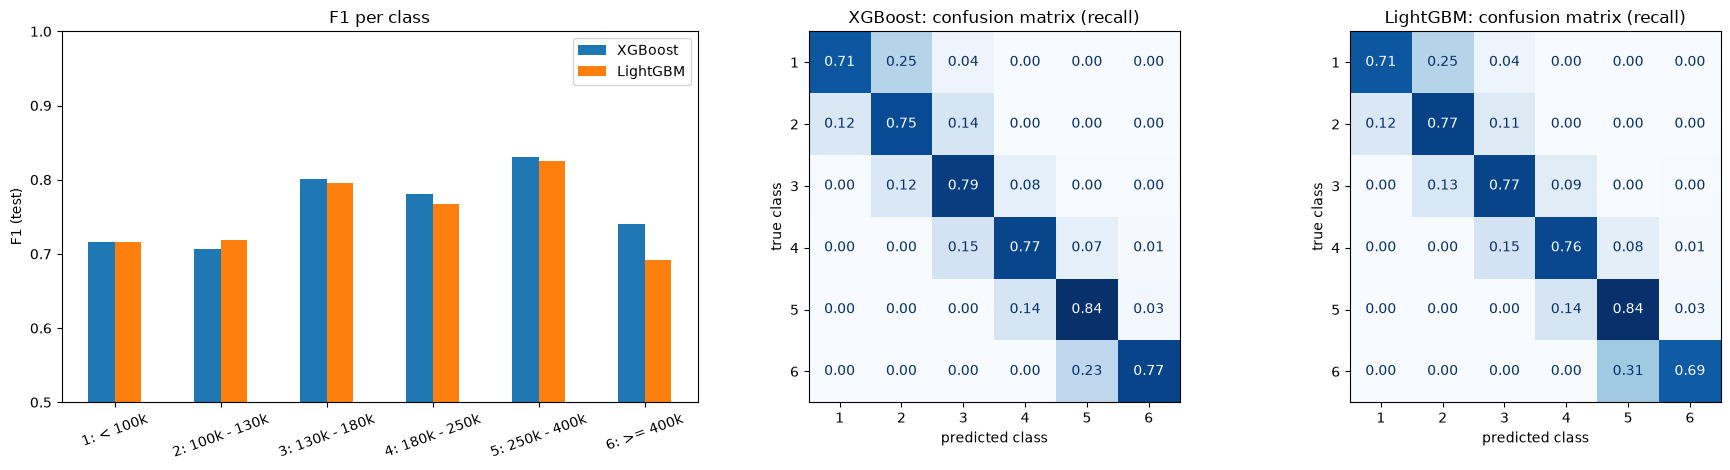

,XGBoost,LightGBM
1: < 100k,0.716,0.716
2: 100k - 130k,0.707,0.718
3: 130k - 180k,0.801,0.795
4: 180k - 250k,0.781,0.768
5: 250k - 400k,0.830,0.825
6: >= 400k,0.741,0.692


In [17]:
per_class = pd.DataFrame({
    "XGBoost": f1_score(y_test, pred_xgb, average=None),
    "LightGBM": f1_score(y_test, pred_lgb, average=None),
}, index=[f"{c}: {label}" for c, label in CLASS_LABELS.items()])

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw={"width_ratios": [1.3, 1, 1]})
per_class.plot.bar(ax=axes[0], rot=20)
axes[0].set(ylabel="F1 (test)", title="F1 per class", ylim=(0.5, 1))
for ax, pred, name in [(axes[1], pred_xgb, "XGBoost"), (axes[2], pred_lgb, "LightGBM")]:
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=list(CLASS_LABELS), normalize="true",
                                            values_format=".2f", cmap="Blues", ax=ax, colorbar=False)
    ax.set(title=f"{name}: confusion matrix (recall)", xlabel="predicted class", ylabel="true class")
plt.tight_layout()
plt.show()
per_class.round(3)

### Feature importance (gain and split)

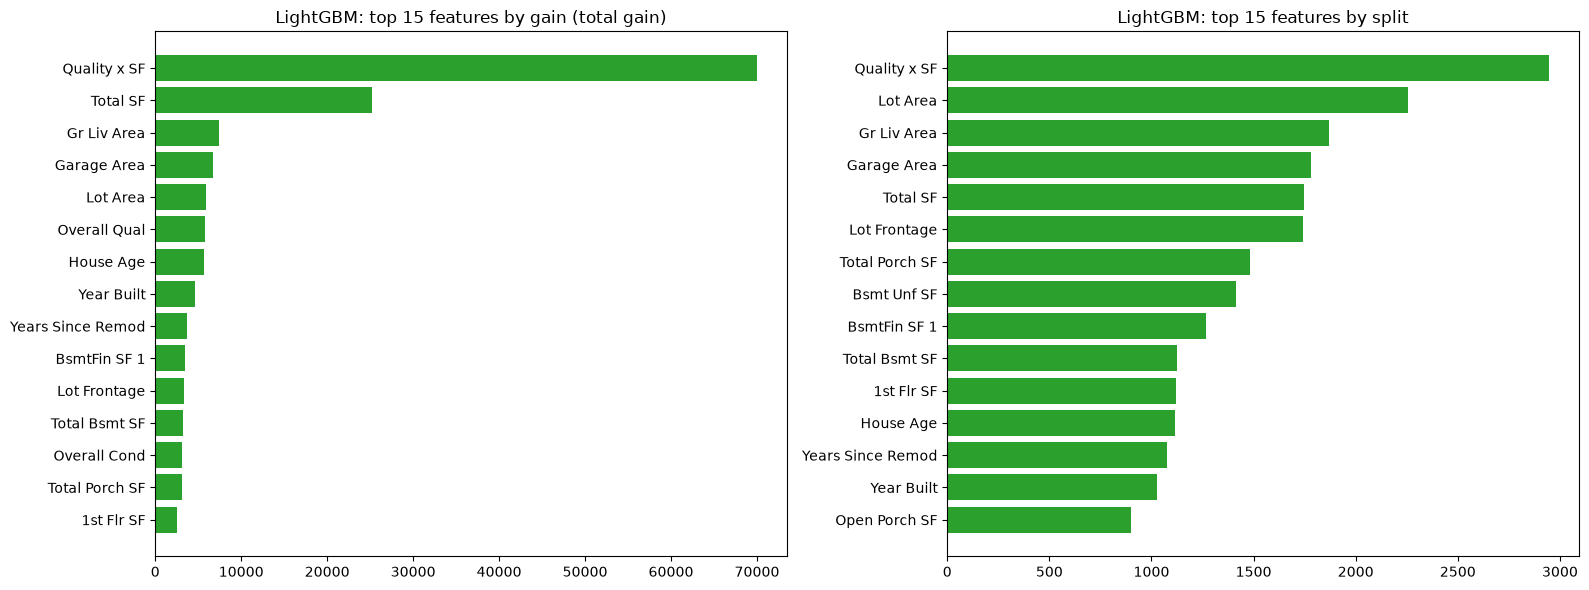

,XGBoost gain rank,LightGBM gain rank,XGBoost split rank,LightGBM split rank
Quality x SF,1,1,1,1
Total SF,2,2,6,5
Gr Liv Area,3,3,4,3
Garage Area,5,4,5,4
Lot Area,6,5,2,2
Overall Qual,8,6,25,25
House Age,9,7,15,12
Year Built,4,8,11,14
Years Since Remod,11,9,14,13
BsmtFin SF 1,15,10,9,9


In [18]:
lgb_booster = final_lgb.booster_
lgb_importance = pd.DataFrame({
    "gain": lgb_booster.feature_importance(importance_type="gain"),
    "split": lgb_booster.feature_importance(importance_type="split"),
}, index=X_train.columns)  # same order as the columns; LightGBM only renamed them
xgb_importance = pd.DataFrame({
    "gain": pd.Series(final_xgb.get_booster().get_score(importance_type="total_gain")),
    "split": pd.Series(final_xgb.get_booster().get_score(importance_type="weight")),
}).reindex(X_train.columns).fillna(0)

TOP = 15
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, kind in zip(axes, ["gain", "split"]):
    top = lgb_importance[kind].nlargest(TOP)[::-1]
    ax.barh(top.index, top.values, color="tab:green")
    ax.set_title(f"LightGBM: top {TOP} features by {kind}" + (" (total gain)" if kind == "gain" else ""))
plt.tight_layout()
plt.show()

ranks = pd.DataFrame({
    "XGBoost gain rank": xgb_importance["gain"].rank(ascending=False, method="min"),
    "LightGBM gain rank": lgb_importance["gain"].rank(ascending=False, method="min"),
    "XGBoost split rank": xgb_importance["split"].rank(ascending=False, method="min"),
    "LightGBM split rank": lgb_importance["split"].rank(ascending=False, method="min"),
}).astype(int)
ranks.sort_values("LightGBM gain rank").head(10)

LightGBM's `gain` importance is the **total** gain of a feature (XGBoost's `total_gain`), so the XGBoost ranks above use `total_gain` too.

**Interpretation — results**
- **Test macro-F1: XGBoost 0.763, LightGBM 0.752.** The bootstrap interval of the difference (≈ [−0.037, +0.010]) contains 0,
  and the CV scores are almost identical (0.773 vs. 0.772) → **no significant difference** between the two models.
- **LightGBM has the better test log-loss (0.562 vs. 0.587)** — its probabilities are better calibrated, as expected from the
  learning curves (XGBoost's probabilities become over-confident after ≈ 100 rounds). Better probabilities do not automatically
  mean better argmax decisions.
- **Per class** the models are within ≈ 0.01 F1 except class 6 (0.74 vs. 0.69): with 13 test houses, this is a difference of
  about one house. The confusion matrices show the same pattern for both — errors only between neighbouring classes.
- **Feature importance is very similar:** `Quality x SF`, `Total SF` and `Gr Liv Area` are the top 3 by gain in both libraries;
  by split, continuous features (`Lot Area`, `Gr Liv Area`, `Garage Area`) dominate in both. Both models learned the same structure
  from the same features.

In [19]:
lgb_summary = {"cv_f1": round(lgb_study.best_value, 4),
               **{f"test_{m}": round(float(v), 4) for m, v in comparison.loc["LightGBM (test)", ["accuracy", "precision", "recall", "f1"]].items()},
               "best_params": lgb_params}
(RESULTS_DIR / "lightgbm_results.json").write_text(json.dumps(lgb_summary, indent=2))

506

## 7. Conclusion

| | XGBoost | LightGBM |
|---|---|---|
| Tree growth | level-wise, balanced | leaf-wise, deep and unbalanced |
| Default CV macro-F1 | 0.749 | 0.748 |
| Tuned CV macro-F1 | **0.773** | 0.772 |
| Test macro-F1 | **0.763** | 0.752 (difference not significant) |
| Test log-loss | 0.587 | **0.562** |
| Optuna search (100 trials) | 44 min | **7.6 min** |
| Time per boosting round | 4.0 ms | **1.9 ms** |
| Tuned trees | depth ≈ 3, ≈ 8 leaves, lr 0.082, 400 rounds | depth ≈ 4, ≈ 10 leaves, lr 0.015, 750 rounds |

- **The two algorithms build trees differently** — balanced vs. best-first — and with the same leaf budget LightGBM fits the data
  faster (more variance per leaf).
- **After tuning they perform the same.** On this small dataset, Optuna restricted LightGBM to shallow trees, so its leaf-wise
  advantage mostly disappears; the limiting factor is the data (class boundaries in a continuous price), not the algorithm.
- **LightGBM's practical advantages** are speed (≈ 2× per round; the search was ≈ 6× faster, partly because trials ran in parallel) and better-calibrated probabilities;
  XGBoost keeps a slight, non-significant edge in macro-F1 and remains our final model.